# M4.9 · 动态风险管理与对冲

> 静态模型假设风险参数恒定，但市场波动聚集、相关性会突变。动态风控根据**最新信息实时调整暴露**：高波降杠杆、用对冲工具剥离风险、回撤触及时止损。

## 一、核心工具

1. **波动率目标（vol targeting）**：目标杠杆 $L_t=\operatorname{clip}(\sigma_{target}/\hat\sigma_t,0,L_{\max})$，用 shift(1) 防未来函数；
2. **最小方差对冲比率**：$\beta^*=\operatorname{Cov}(r_a,r_h)/\operatorname{Var}(r_h)$，对冲后残差波动最小；
3. **回撤止损/去杠杆**：净值相对峰值回撤 $DD_t=E_t/\max E-1$ 触及阈值即触发；
4. **杠杆倍数**：$(\text{权益}+\text{负债})/\text{权益}$。

## 二、波动率目标

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import hedging, products
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
r1 = ret.iloc[:, 0].dropna()
strat, lev = hedging.apply_vol_target(r1, target_vol=0.12, window=20, max_lev=1.5)
realized = r1.rolling(20).std()*np.sqrt(242)
print('原始年化波动=%.4f 波动率目标策略年化波动=%.4f'
      % (r1.std()*np.sqrt(242), strat.std()*np.sqrt(242)))
print('杠杆范围 [%.3f, %.3f] 末杠杆=%.3f' % (lev.min(), lev.max(), lev.iloc[-1]))

[1476:MainThread](2026-11-05 14:38:11,972) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[1476:MainThread](2026-11-05 14:38:13,990) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[1476:MainThread](2026-11-05 14:38:13,991) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


原始年化波动=0.1995 波动率目标策略年化波动=0.1382
杠杆范围 [0.276, 1.500] 末杠杆=0.617


## 三、最小方差对冲与回撤止损

In [2]:
r50 = ret.iloc[-750:, :50].dropna(axis=1)
mkt = r50.mean(axis=1)
mh = hedging.min_variance_hedge(r1, mkt)
print('对冲比率 beta=%.4f 对冲前波动=%.4f 对冲后波动=%.4f 波动下降=%.2f%%'
      % (mh['beta'], mh['raw_vol'], mh['hedged_vol'], mh['vol_reduction']*100))
eq = (1+r1).cumprod()
ds = hedging.drawdown_stop(eq, 0.15)
print('最大回撤=%.4f 止损触发次数=%d 首次触发=%s'
      % (ds['max_drawdown'], ds['n_breach'], str(ds['first_trigger'])[:10]))
print('权益100万、负债50万时杠杆=%.2f' % hedging.leverage_from_margin(1e6, 5e5))

对冲比率 beta=0.4660 对冲前波动=0.2178 对冲后波动=0.2039 波动下降=6.36%
最大回撤=-0.4105 止损触发次数=1559 首次触发=2018-03-28
权益100万、负债50万时杠杆=1.50


## 四、可视化

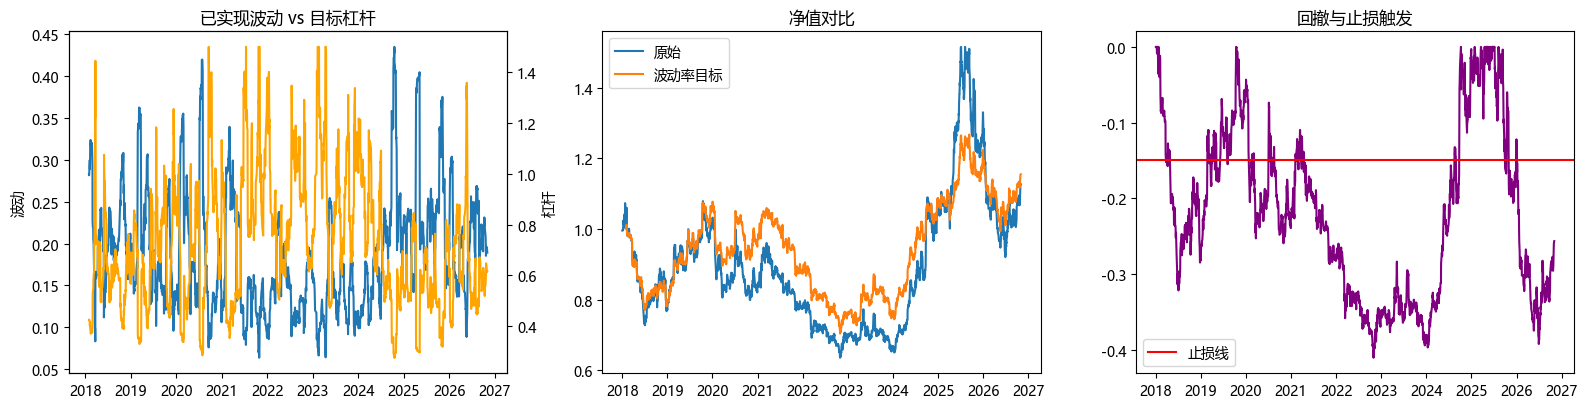

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(realized.index, realized.values, label='已实现年化波动')
ax0b = ax[0].twinx(); ax0b.plot(lev.index, lev.values, color='orange', label='目标杠杆')
ax[0].set_title('已实现波动 vs 目标杠杆'); ax[0].set_ylabel('波动'); ax0b.set_ylabel('杠杆')
ax[1].plot((1+r1).cumprod().index, (1+r1).cumprod().values, label='原始')
ax[1].plot((1+strat).cumprod().index, (1+strat).cumprod().values, label='波动率目标')
ax[1].set_title('净值对比'); ax[1].legend()
dd = eq/eq.cummax()-1
ax[2].plot(dd.index, dd.values, color='purple'); ax[2].axhline(-0.15, color='red', label='止损线')
ax[2].set_title('回撤与止损触发'); ax[2].legend()
plt.tight_layout(); plt.show()

## 五、面试要点

- **波动率目标如何在危机中起作用？** 波动聚集使高波期可预测，策略在波动飙升时自动降杠杆，减小回撤；但会在急跌中「卖在低点」，存在反转成本。
- **为什么要 shift(1)？** 今日杠杆只能基于昨日及之前的信息，否则用未来波动率构成前视偏差。
- **最小方差对冲与 beta 中性的关系？** 最小方差对冲比率即 OLS 斜率，使对冲后残差方差最小；若要完全剥离系统性风险需 beta=1 的期货。
- **止损规则的局限？** 固定回撤阈值在震荡市会反复触发（本数据触发 1500+ 次），常结合波动率/状态过滤。
- **杠杆封顶为何必要？** 低波期 target/σ 会给出极大杠杆，封顶防止过度冒险。

## 六、练习

1. 改变目标波动（0.08/0.12/0.20）与窗口，比较策略夏普与回撤。
2. 用股指期货收益替代等权市场，重新计算对冲比率。
3. 给止损加「连续 N 日确认」条件，统计触发次数变化。
4. 思考波动率目标策略在 2015 年式急跌中的表现与缺陷。